In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("train.csv")
public_test = pd.read_csv("public_test.csv")
private_test = pd.read_csv("private_test.csv")

print("Train Shape:", train.shape)
print("Public Test Shape:", public_test.shape)
print("Private Test Shape:", private_test.shape)

train.head()


Train Shape: (10000, 14)
Public Test Shape: (3000, 14)
Private Test Shape: (3000, 13)


,User_ID,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code,Converted
0,1,58.0,103593.708812,2,Mobile,Organic,5,4,9.61,3,0,11,2418,0
1,2,26.0,36451.716984,2,Mobile,Social Media,11,3,17.63,2,0,14,1213,0
2,3,19.0,30511.228700,3,Mobile,Referral,1,1,13.25,5,0,5,2849,0
3,4,48.0,87789.172342,3,Mobile,Email,14,12,NaN,1,1,19,7610,0
4,5,35.0,105229.249067,2,Mobile,Social Media,14,21,16.92,1,0,5,9261,0


In [3]:
num_col = train.select_dtypes(include = 'number').columns.tolist()
cat_col = [col for col in train if col not in num_col]

In [4]:
train.groupby('Converted')[num_col].mean()

,User_ID,Age,Income,City_Tier,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code,Converted
Converted,,,,,,,,,,,,
0,4998.182844,41.548475,69134.659095,1.935918,13.802546,13.360480,12.597556,2.859974,0.505135,12.480255,5525.615507,0.0
1,5005.689018,41.253435,71771.595850,1.927762,19.652737,19.381924,15.925828,3.224490,0.620343,12.459670,5478.795594,1.0


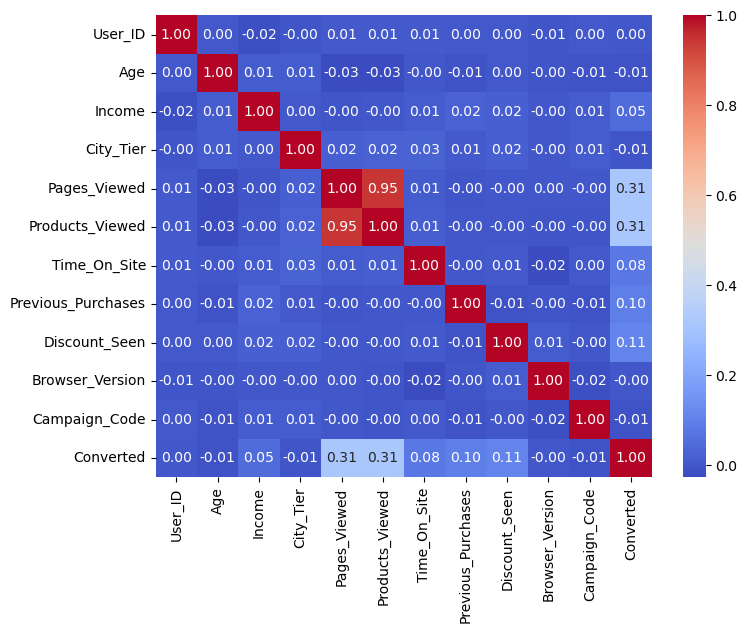

In [5]:
plt.figure(figsize =(8,6))
sns.heatmap(train[num_col].corr(),annot = True,cmap= 'coolwarm',fmt=".2f")
plt.show()

In [6]:
for col in cat_col:
    print(col)

Device_Type
Traffic_Source


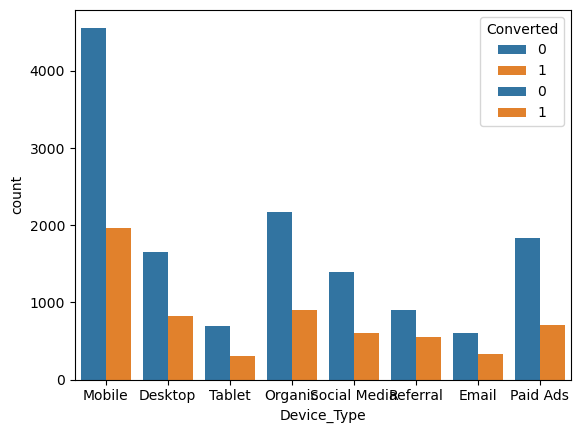

In [7]:
for col in cat_col:
    sns.countplot(data=train, x=col, hue='Converted')

In [8]:
train.drop('User_ID',axis = 1,inplace = True)
train.head(1)

,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code,Converted
0,58.0,103593.708812,2,Mobile,Organic,5,4,9.61,3,0,11,2418,0


In [9]:
train['Campaign_Code'].nunique()

6014

In [10]:
train.drop('Campaign_Code',axis = 1,inplace = True)
train.head(1)

,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Converted
0,58.0,103593.708812,2,Mobile,Organic,5,4,9.61,3,0,11,0


In [11]:
num_col = [col for col in num_col if col not in ['Campaign_Code', 'User_ID']]

## Now Lets DO MISSING handlingggg

In [12]:
train.isnull().sum()/len(train)*100

Age                   14.80
Income                 9.84
City_Tier              0.00
Device_Type            0.00
Traffic_Source         0.00
Pages_Viewed           0.00
Products_Viewed        0.00
Time_On_Site          18.48
Previous_Purchases     0.00
Discount_Seen          0.00
Browser_Version        0.00
Converted              0.00
dtype: float64

In [13]:
missing_cols = ['Age','Time_On_Site','Income']

In [14]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = 'median')

In [15]:
imputer.fit(train[missing_cols])

train[missing_cols] = imputer.transform(train[missing_cols])
public_test[missing_cols] = imputer.transform(public_test[missing_cols])
private_test[missing_cols] = imputer.transform(private_test[missing_cols])

## Encoding (one hot encode)

In [16]:
train = pd.get_dummies(train, columns=cat_col)
public_test = pd.get_dummies(public_test, columns=cat_col)
private_test = pd.get_dummies(private_test, columns=cat_col)


public_test = public_test.reindex(columns=train.columns, fill_value=0)
private_test = private_test.reindex(columns=train.columns, fill_value=0)

private_test.drop('Converted',inplace= True,axis = 1)

In [17]:
private_test.head()

,Age,Income,City_Tier,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Device_Type_Desktop,Device_Type_Mobile,Device_Type_Tablet,Traffic_Source_Email,Traffic_Source_Organic,Traffic_Source_Paid Ads,Traffic_Source_Referral,Traffic_Source_Social Media
0,54.0,12000.000000,2,3,1,13.140,3,0,9,False,True,False,True,False,False,False,False
1,59.0,70171.613672,3,22,20,11.145,4,0,18,False,True,False,False,True,False,False,False
2,41.0,79296.908337,2,28,24,3.360,1,0,2,False,True,False,False,False,True,False,False
3,19.0,65279.025663,2,20,13,8.780,6,1,5,False,True,False,False,False,False,False,True
4,31.0,70171.613672,3,10,15,24.140,5,0,20,False,True,False,False,False,True,False,False


## Scaling 

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [19]:
scale_col = [col for col in num_col if col not in ['Converted', 'Discount_Seen', 'User_ID', 'Campaign_Code']]
train[scale_col] = scaler.fit_transform(train[scale_col])

public_test[scale_col] = scaler.transform(public_test[scale_col])
private_test[scale_col] = scaler.transform(private_test[scale_col])

In [20]:
train.head()

,Age,Income,City_Tier,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Converted,Device_Type_Desktop,Device_Type_Mobile,Device_Type_Tablet,Traffic_Source_Email,Traffic_Source_Organic,Traffic_Source_Paid Ads,Traffic_Source_Referral,Traffic_Source_Social Media
0,1.306775,1.427948,0.090284,-1.230252,-1.256766,-0.204312,0.015817,0,-0.213841,0,False,True,False,False,True,False,False,False
1,-1.210792,-1.424525,0.090284,-0.534441,-1.368785,0.251974,-0.559357,0,0.221414,0,False,True,False,False,False,False,False,True
2,-1.761510,-1.676901,1.445894,-1.694126,-1.592821,0.002780,1.166166,0,-1.084351,0,False,True,False,False,False,False,True,False
3,0.520035,0.756505,1.445894,-0.186535,-0.360620,-0.116981,-1.134531,1,0.946839,0,False,True,False,True,False,False,False,False
4,-0.502727,1.497433,0.090284,-0.186535,0.647544,0.211580,-1.134531,0,-1.084351,0,False,True,False,False,False,False,False,True


## Model Training

In [21]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000, random_state=43, class_weight = 'balanced')

In [22]:
depend_col = [col for col in train.columns if col != 'Converted']

X_train = train[depend_col]
y_train = train['Converted']

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,43
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [23]:
print("Model trained successfully!")
print("Training Accuracy: {:.4f}".format(model.score(X_train, y_train)))

Model trained successfully!
Training Accuracy: 0.6740


## Score check

In [24]:
from sklearn.metrics import f1_score

X_pub = public_test[depend_col]
y_pub = public_test['Converted']  

preds = model.predict(X_pub)
print(f1_score(y_pub, preds))


0.5405405405405406


In [25]:
X_private = private_test[depend_col]


predictions = model.predict(X_private)

private_test_copy = pd.read_csv("private_test.csv")
submission = pd.DataFrame({
    "User_ID": private_test_copy["User_ID"],
    "Converted": predictions
})

submission.to_csv("submission.csv", index=False)

print("submission.csv created successfully!")
submission.head()


submission.csv created successfully!


,User_ID,Converted
0,103001,0
1,103002,1
2,103003,0
3,103004,1
4,103005,0
